In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [38]:
category_frequency_table = df['category'].value_counts()
category_frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [39]:
top5_categories = category_frequency_table.head(5)
top5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

Top 5 most listed categories:

Sports & Outdoors
Beauty
Handmade Clothing, Shoes & Accessories
Bath & Body
Birthday Gifts

Does any category dominate?
Yes. Sports & Outdoors has about 836,000 listings, while each of the other four has roughly 19,000–20,000. That means Sports & Outdoors makes up about 90% of the top 5 combined, so the other four categories are tiny in comparison.

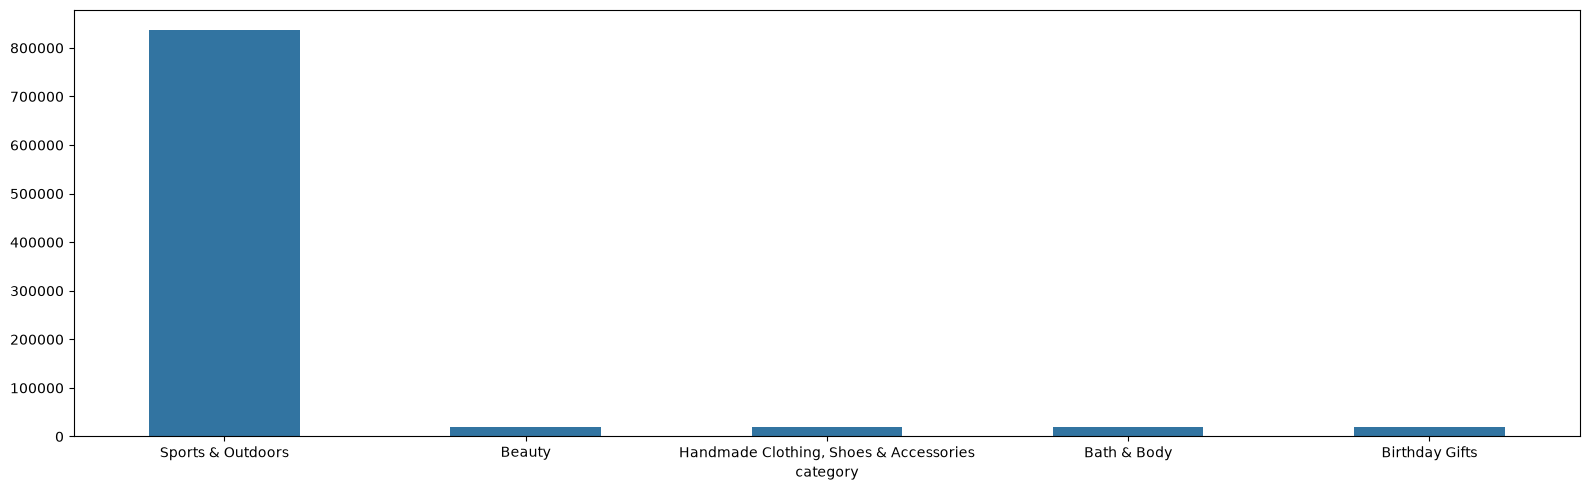

In [41]:
plt.figure(figsize=(16, 5))
sns.barplot(x=top5_categories.index, y=top5_categories.values, width=0.5)
plt.tight_layout()
plt.show()

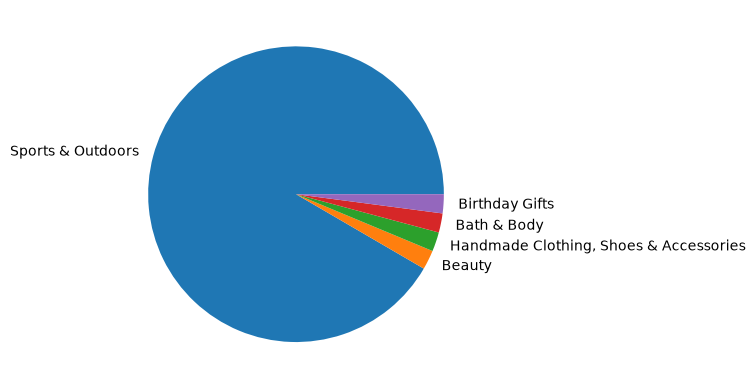

In [43]:
plt.pie(top5_categories, labels=top5_categories.index)
plt.show()

In [45]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print("Mean price: £", round(mean_price, 2))
print("Median price: £", round(median_price, 2))
print("Mode price: £", round(mode_price, 2))

Mean price: £ 89.24
Median price: £ 19.09
Mode price: £ 9.99


The average listed price is £89.24, but the most common price is only £9.99, because a small number of expensive products pull the average far above what a typical product costs.

In [48]:
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr_price = q3 - q1

print("Variance:", round(variance_price, 2))
print("Standard deviation: £", round(std_dev_price, 2))
print("Min price: £", round(min_price, 2))
print("Max price: £", round(max_price, 2))
print("Range: £", round(range_price, 2))
print("25% quartile: £", round(q1, 2))
print("75% quartile: £", round(q3, 2))
print("IQR: £", round(iqr_price, 2))

Variance: 119445.49
Standard deviation: £ 345.61
Min price: £ 0.0
Max price: £ 100000.0
Range: £ 100000.0
25% quartile: £ 9.99
75% quartile: £ 45.99
IQR: £ 36.0


Prices are extremely spread out: the standard deviation (£345.61) is almost four times the mean (£89.24), and the range is £100,000, yet the middle half of products sits between £9.99 and £45.99 (IQR £36), so a few extreme prices create most of the spread.

The min of £0 and max of £100,000 are suspicious. A £0 product and a £100,000 product may be data errors or placeholder values rather than real prices. It’s worth a sentence in your notebook, and you’ll see the expensive ones clearly in the box plot.

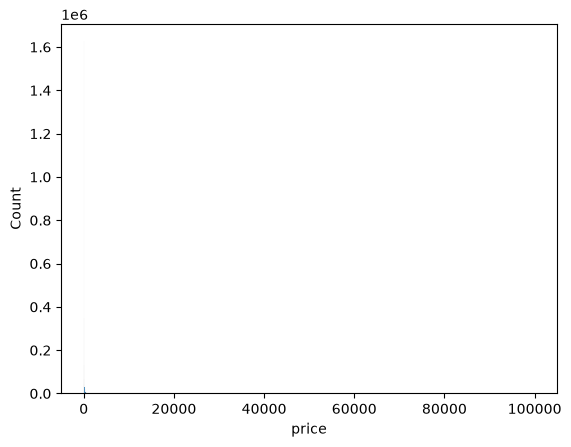

In [49]:
sns.histplot(df['price'])
plt.show()

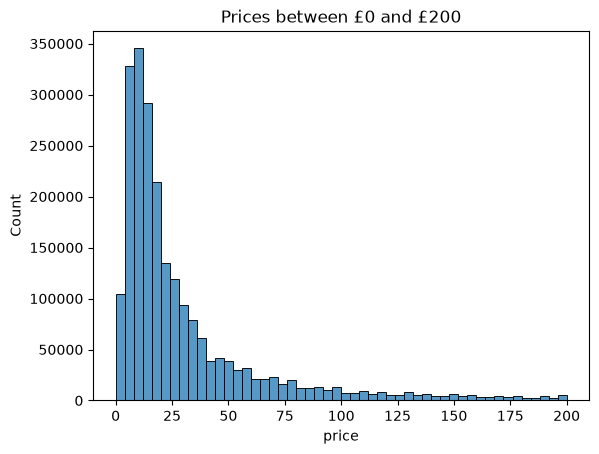

In [51]:
cheap_products = df[(df['price'] > 0) & (df['price'] < 200)]
sns.histplot(cheap_products['price'], bins=50)
plt.title("Prices between £0 and £200")
plt.show()

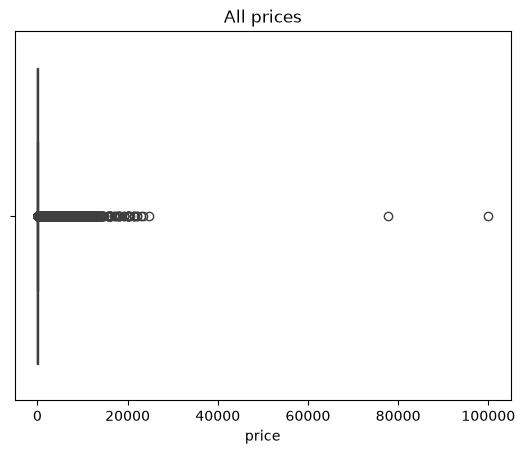

In [54]:
sns.boxplot(x=df['price'])
plt.title("All prices")
plt.show()

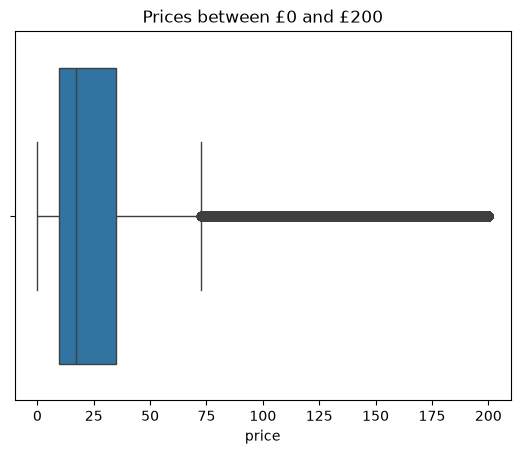

In [53]:
cheap_products = df[(df['price'] > 0) & (df['price'] < 200)]
sns.boxplot(x=cheap_products['price'])
plt.title("Prices between £0 and £200")
plt.show()

In [55]:
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]

print("Mean rating:", round(mean_rating, 2))
print("Median rating:", round(median_rating, 2))
print("Mode rating:", round(mode_rating, 2))

Mean rating: 2.15
Median rating: 0.0
Mode rating: 0.0


In [57]:
rated_products = df[df['stars'] > 0]

mean_rated = rated_products['stars'].mean()
median_rated = rated_products['stars'].median()
mode_rated = rated_products['stars'].mode()[0]

print("Rated products only:")
print("Mean rating:", round(mean_rated, 2))
print("Median rating:", round(median_rated, 2))
print("Mode rating:", round(mode_rated, 2))

Rated products only:
Mean rating: 4.32
Median rating: 4.4
Mode rating: 4.5


Across all products the mean rating is 2.15 and the median and mode are 0, because most products have no reviews yet and are stored as 0 stars; among rated products only, the mean is 4.32, the median 4.4 and the mode 4.5, so products that do get reviewed are rated highly, and from here on we analyse rated products only, since the zeros mean “no rating” rather than a real score.

In [58]:
variance_rating = rated_products['stars'].var()
std_dev_rating = rated_products['stars'].std()
q1_rating = rated_products['stars'].quantile(0.25)
q3_rating = rated_products['stars'].quantile(0.75)
iqr_rating = q3_rating - q1_rating

print("Rated products only:")
print("Variance:", round(variance_rating, 2))
print("Standard deviation:", round(std_dev_rating, 2))
print("25% quartile:", round(q1_rating, 2))
print("75% quartile:", round(q3_rating, 2))
print("IQR:", round(iqr_rating, 2))

Rated products only:
Variance: 0.31
Standard deviation: 0.56
25% quartile: 4.1
75% quartile: 4.6
IQR: 0.5


Among rated products, ratings vary very little: the standard deviation is only 0.56 stars and the middle half of products sits between 4.1 and 4.6 (IQR 0.5), so most reviewed products get consistently high ratings.

In [59]:
skew_rating = rated_products['stars'].skew()
kurt_rating = rated_products['stars'].kurt()

print("Skewness:", round(skew_rating, 2))
print("Kurtosis:", round(kurt_rating, 2))

Skewness: -2.38
Kurtosis: 9.78


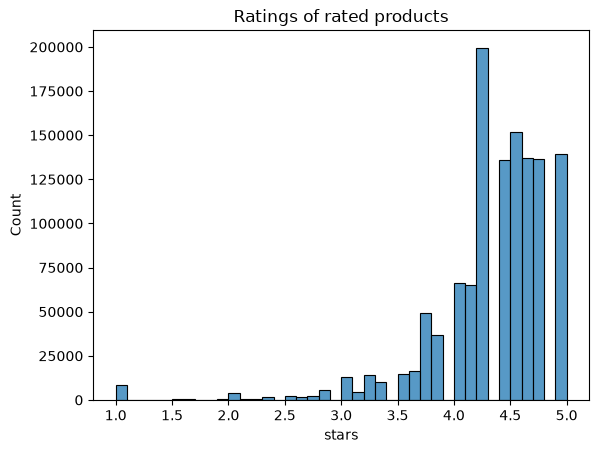

In [60]:
sns.histplot(rated_products['stars'], bins=40)
plt.title("Ratings of rated products")
plt.show()

Ratings are not normally distributed: the skewness of −2.38 shows they lean strongly towards higher values, with a long tail of fewer low ratings, and the kurtosis of 9.78 shows a very sharp peak, with most products bunched around 4.5 stars, the most common rating.